# 01 - Data Collection
LULC Sentinel-1 Project: pulls Sentinel-1 (VV, VH) and ESA WorldCover labels for 5 German cities (Kiel, Leipzig, Dresden, Rostock, Munster), exports to Google Drive, and includes a city land-mix check and a metadata CSV.

## Cell 1: Install packages

In [1]:
!pip install earthengine-api geemap -q

## Cell 2: Authenticate and initialize Earth Engine

In [2]:
import ee

ee.Authenticate()
ee.Initialize(project='lulc-sentinel1')

## Cell 3: Define all 5 city bounding boxes

In [3]:
cities = {
    "Kiel": ee.Geometry.Rectangle([10.05, 54.27, 10.25, 54.38]),
    "Leipzig": ee.Geometry.Rectangle([12.30, 51.28, 12.48, 51.40]),
    "Dresden": ee.Geometry.Rectangle([13.65, 51.00, 13.85, 51.12]),
    "Rostock": ee.Geometry.Rectangle([12.05, 54.03, 12.20, 54.20]),
    "Munster": ee.Geometry.Rectangle([7.55, 51.90, 7.70, 52.00]),
}

for name, geom in cities.items():
    print(name, geom.bounds().getInfo()['coordinates'])

Kiel [[[10.05, 54.269999999999975], [10.25, 54.269999999999975], [10.25, 54.380041315183746], [10.05, 54.380041315183746], [10.05, 54.269999999999975]]]
Leipzig [[[12.3, 51.27999999999998], [12.48, 51.27999999999998], [12.48, 51.40003446463256], [12.3, 51.40003446463256], [12.3, 51.27999999999998]]]
Dresden [[[13.649999999999999, 50.99999999999997], [13.85, 50.99999999999997], [13.85, 51.12004264138091], [13.649999999999999, 51.12004264138091], [13.649999999999999, 50.99999999999997]]]
Rostock [[[12.049999999999999, 54.02999999999998], [12.200000000000001, 54.02999999999998], [12.200000000000001, 54.20002328892472], [12.049999999999999, 54.20002328892472], [12.049999999999999, 54.02999999999998]]]
Munster [[[7.549999999999998, 51.89999999999996], [7.699999999999999, 51.89999999999996], [7.699999999999999, 52.00002381464443], [7.549999999999998, 52.00002381464443], [7.549999999999998, 51.89999999999996]]]


## Cell 4: [BONUS] Land mix check per city
Pulls real class percentages from ESA WorldCover for each city


In [4]:
worldcover = ee.ImageCollection('ESA/WorldCover/v200').first()

class_names = {
    10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland",
    50: "Built-up", 60: "Bare/sparse vegetation", 70: "Snow/ice",
    80: "Permanent water", 90: "Herbaceous wetland", 95: "Mangroves", 100: "Moss/lichen"
}

city_land_mix = {}

for city, geom in cities.items():
    clipped = worldcover.clip(geom)
    hist = clipped.reduceRegion(
        reducer=ee.Reducer.frequencyHistogram(),
        geometry=geom,
        scale=100,
        maxPixels=1e9
    ).getInfo()

    counts = hist['Map']
    total = sum(counts.values())
    pct_by_class = {}

    print(f"\n=== {city} ===")
    sorted_classes = sorted(counts.items(), key=lambda x: -x[1])
    for code, count in sorted_classes:
        pct = (count / total) * 100
        name = class_names.get(int(float(code)), f"Unknown ({code})")
        pct_by_class[name] = round(pct, 1)
        print(f"{name}: {pct:.1f}%")

    city_land_mix[city] = pct_by_class


=== Kiel ===
Tree cover: 46.8%
Built-up: 18.6%
Cropland: 13.7%
Grassland: 11.4%
Permanent water: 9.4%
Herbaceous wetland: 0.0%
Bare/sparse vegetation: 0.0%

=== Leipzig ===
Tree cover: 39.3%
Built-up: 37.2%
Grassland: 13.1%
Cropland: 9.6%
Permanent water: 0.8%
Bare/sparse vegetation: 0.1%

=== Dresden ===
Tree cover: 52.1%
Built-up: 32.6%
Grassland: 9.5%
Cropland: 4.1%
Permanent water: 1.7%
Bare/sparse vegetation: 0.1%

=== Rostock ===
Tree cover: 30.4%
Cropland: 18.5%
Grassland: 18.4%
Built-up: 16.6%
Permanent water: 13.8%
Herbaceous wetland: 2.0%
Bare/sparse vegetation: 0.3%

=== Munster ===
Tree cover: 43.4%
Built-up: 27.0%
Cropland: 16.9%
Grassland: 11.6%
Permanent water: 1.0%
Bare/sparse vegetation: 0.1%


## Cell 5: Mount Google Drive (export destination for the full dataset)

In [5]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_FOLDER = '/content/drive/MyDrive/lulc_dataset'
os.makedirs(DRIVE_FOLDER, exist_ok=True)
print("Export folder ready at:", DRIVE_FOLDER)

Mounted at /content/drive
Export folder ready at: /content/drive/MyDrive/lulc_dataset


## Cell 6: Define the Sentinel-1 + WorldCover pulling function
Pulls one Sentinel-1 VV/VH monthly composite and the WorldCover label for a given city and month

In [6]:
import calendar

def get_month_range(year, month):
    start = f"{year}-{month:02d}-01"
    last_day = calendar.monthrange(year, month)[1]
    end = f"{year}-{month:02d}-{last_day:02d}"
    return start, end

def export_city_month(city_name, geom, year, month):
    start, end = get_month_range(year, month)

    s1 = ee.ImageCollection('COPERNICUS/S1_GRD') \
        .filterBounds(geom) \
        .filterDate(start, end) \
        .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')) \
        .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')) \
        .filter(ee.Filter.eq('instrumentMode', 'IW'))

    count = s1.size().getInfo()
    if count == 0:
        print(f"  [SKIP] {city_name} {year}-{month:02d}: no Sentinel-1 images found")
        return None

    s1_image = s1.median().select(['VV', 'VH']).clip(geom)
    worldcover_img = ee.ImageCollection('ESA/WorldCover/v200').first().clip(geom)

    tag = f"{city_name}_{year}_{month:02d}"

    s1_task = ee.batch.Export.image.toDrive(
        image=s1_image,
        description=f"s1_{tag}",
        folder='lulc_dataset',
        fileNamePrefix=f"s1_{tag}",
        region=geom,
        scale=10,
        maxPixels=1e9
    )
    s1_task.start()

    wc_task = ee.batch.Export.image.toDrive(
        image=worldcover_img,
        description=f"wc_{tag}",
        folder='lulc_dataset',
        fileNamePrefix=f"wc_{tag}",
        region=geom,
        scale=10,
        maxPixels=1e9
    )
    wc_task.start()

    print(f"  [EXPORT STARTED] {tag} ({count} Sentinel-1 images found)")
    return {
        "city": city_name,
        "year": year,
        "month": month,
        "s1_file": f"s1_{tag}.tif",
        "wc_file": f"wc_{tag}.tif",
        "s1_image_count": count,
    }

## Cell 7: Loop through all 5 cities and 12 months, start all exports
Uses Nov 2025 to Oct 2026 as the 12-month window.


In [7]:
MONTHS = [
    (2025, 11), (2025, 12), (2026, 1), (2026, 2), (2026, 3), (2026, 4),
    (2026, 5), (2026, 6), (2026, 7), (2026, 8), (2026, 9), (2026, 10),
]

metadata_records = []

for city_name, geom in cities.items():
    print(f"\n--- {city_name} ---")
    for year, month in MONTHS:
        record = export_city_month(city_name, geom, year, month)
        if record:
            metadata_records.append(record)


--- Kiel ---
  [EXPORT STARTED] Kiel_2025_11 (23 Sentinel-1 images found)
  [EXPORT STARTED] Kiel_2025_12 (23 Sentinel-1 images found)
  [EXPORT STARTED] Kiel_2026_01 (26 Sentinel-1 images found)
  [EXPORT STARTED] Kiel_2026_02 (23 Sentinel-1 images found)
  [EXPORT STARTED] Kiel_2026_03 (26 Sentinel-1 images found)
  [EXPORT STARTED] Kiel_2026_04 (28 Sentinel-1 images found)
  [EXPORT STARTED] Kiel_2026_05 (35 Sentinel-1 images found)
  [EXPORT STARTED] Kiel_2026_06 (29 Sentinel-1 images found)
  [EXPORT STARTED] Kiel_2026_07 (20 Sentinel-1 images found)
  [EXPORT STARTED] Kiel_2026_08 (21 Sentinel-1 images found)
  [EXPORT STARTED] Kiel_2026_09 (19 Sentinel-1 images found)
  [EXPORT STARTED] Kiel_2026_10 (19 Sentinel-1 images found)

--- Leipzig ---
  [EXPORT STARTED] Leipzig_2025_11 (19 Sentinel-1 images found)
  [EXPORT STARTED] Leipzig_2025_12 (20 Sentinel-1 images found)
  [EXPORT STARTED] Leipzig_2026_01 (20 Sentinel-1 images found)
  [EXPORT STARTED] Leipzig_2026_02 (18 Sentin

## Cell 8: Check export task status


In [63]:
tasks = ee.batch.Task.list()

status_counts = {}
for t in tasks[:len(metadata_records) * 2]:
    status = t.status()['state']
    status_counts[status] = status_counts.get(status, 0) + 1

print("Task status summary:", status_counts)

Task status summary: {'COMPLETED': 120}


## Cell 9:  Save metadata CSV
Records city, year, month, file names, and image counts for every exported pair. Makes the dataset easy to describe and reload later.

In [64]:
import pandas as pd

metadata_df = pd.DataFrame(metadata_records)
metadata_csv_path = f"{DRIVE_FOLDER}/dataset_metadata.csv"
metadata_df.to_csv(metadata_csv_path, index=False)

print(f"Saved metadata for {len(metadata_df)} city-month pairs to {metadata_csv_path}")
metadata_df.head(10)

Saved metadata for 60 city-month pairs to /content/drive/MyDrive/lulc_dataset/dataset_metadata.csv


,city,year,month,s1_file,wc_file,s1_image_count
0,Kiel,2025,11,s1_Kiel_2025_11.tif,wc_Kiel_2025_11.tif,23
1,Kiel,2025,12,s1_Kiel_2025_12.tif,wc_Kiel_2025_12.tif,23
2,Kiel,2026,1,s1_Kiel_2026_01.tif,wc_Kiel_2026_01.tif,26
3,Kiel,2026,2,s1_Kiel_2026_02.tif,wc_Kiel_2026_02.tif,23
4,Kiel,2026,3,s1_Kiel_2026_03.tif,wc_Kiel_2026_03.tif,26
5,Kiel,2026,4,s1_Kiel_2026_04.tif,wc_Kiel_2026_04.tif,28
6,Kiel,2026,5,s1_Kiel_2026_05.tif,wc_Kiel_2026_05.tif,35
7,Kiel,2026,6,s1_Kiel_2026_06.tif,wc_Kiel_2026_06.tif,29
8,Kiel,2026,7,s1_Kiel_2026_07.tif,wc_Kiel_2026_07.tif,20
9,Kiel,2026,8,s1_Kiel_2026_08.tif,wc_Kiel_2026_08.tif,21


## Cell 10: Visual confirmation
Once exports finish (check Cell 8), load one sample city's Sentinel-1 and WorldCover file from Drive and display them side by side. This is the execution-result/visualization proof required for the notebook submission.

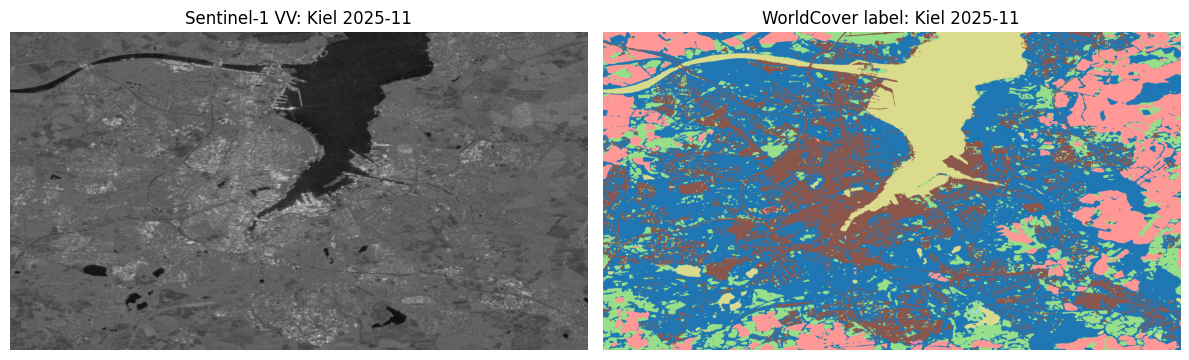

In [66]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np

sample_tag = metadata_records[0]
s1_path = f"{DRIVE_FOLDER}/{sample_tag['s1_file']}"
wc_path = f"{DRIVE_FOLDER}/{sample_tag['wc_file']}"

with rasterio.open(s1_path) as src:
    s1_data = src.read(1)

with rasterio.open(wc_path) as src:
    wc_data = src.read(1)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(s1_data, cmap='gray')
axes[0].set_title(f"Sentinel-1 VV: {sample_tag['city']} {sample_tag['year']}-{sample_tag['month']:02d}")
axes[0].axis('off')

axes[1].imshow(wc_data, cmap='tab20')
axes[1].set_title(f"WorldCover label: {sample_tag['city']} {sample_tag['year']}-{sample_tag['month']:02d}")
axes[1].axis('off')

plt.tight_layout()
plt.show()